# Two identical, independent sites on the ligand: single-cycle kinetics (SCK)

Parameter-recovery benchmark. This notebook is AI generated.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.1 RU is added (Rmax = 50 RU).


## Model

The immobilised ligand $P$ has two identical binding sites for the analyte $L$. $f_{PL}$ and $f_{LPL}$ are the fractions of ligand with one and two analytes bound; $f_P = 1 - f_{PL} - f_{LPL}$. With statistical factors for the two sites:

$$\frac{df_{PL}}{dt} = 2k_{on}C f_P - k_{off} f_{PL} - k_{on} C f_{PL} + 2k_{off} f_{LPL}$$

$$\frac{df_{LPL}}{dt} = k_{on} C f_{PL} - 2k_{off} f_{LPL}$$

$$\text{signal} = R_{max,PL}\,f_{PL} + R_{max,LPL}\,f_{LPL}$$

$R_{max,LPL} = 2R_{max,PL}$: each bound analyte adds the same mass.

pykingenie reports `Kd [µM]` and `k_off [1/s]` per site, `Rmax_PL` and `Rmax_LPL`.

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_sck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

The concentrations are injected one after the other without regeneration: 120 s of injection and 60 s of buffer each, and 900 s of buffer after the last injection. Sampling every 1 s.

In [2]:
params = dict(kon=1.0, koff=0.01, Rmax_PL=25.0, Rmax_LPL=50.0)
concs = [0.0011, 0.0033, 0.01, 0.03, 0.09]  # µM, Kd per site = 0.01 µM

true_values = {'Kd': params['koff'] / params['kon'], 'k_off': params['koff'],
               'Rmax_PL': params['Rmax_PL'], 'Rmax_LPL': params['Rmax_LPL']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    fPL, fLPL = y
    fP = 1 - fPL - fLPL
    dfPL = 2 * p['kon'] * conc * fP - p['koff'] * fPL - p['kon'] * conc * fPL + 2 * p['koff'] * fLPL
    dfLPL = p['kon'] * conc * fPL - 2 * p['koff'] * fLPL
    return [dfPL, dfLPL]


def signal(y, p):
    return p['Rmax_PL'] * y[:, 0] + p['Rmax_LPL'] * y[:, 1]


y0 = [0.0, 0.0]

## Simulate the data

In [4]:
data = simulate_sck(rhs, signal, y0, params, concs, assoc_time=120.0, disso_time=60.0, final_disso_time=900.0, dt=1.0,
                    noise_sd=0.1, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=True,
)
fitter.get_steady_state()
fitter.fit_two_site_assoc_and_disso(shared_smax=True)
fitter.fit_params_kinetics

,Kd [µM],k_off [1/s],Rmax_PL,Rmax_LPL,(Derived) k_on [1/µM/s]
0,0.009965,0.009986,24.905162,49.999957,1.002115


## Compare with the true parameters

In [6]:
df = fitter.fit_params_kinetics
fitted_values = {'Kd': fitter.Kd, 'k_off': fitter.k_off,
                 'Rmax_PL': df['Rmax_PL'].iloc[0], 'Rmax_LPL': df['Rmax_LPL'].iloc[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: -0.38% (Rmax_PL)


,true,fitted,rel. error (%),recovered
parameter,,,,
Kd,0.01,0.009965,-0.347505,True
k_off,0.01,0.009986,-0.136692,True
Rmax_PL,25.00,24.905162,-0.379351,True
Rmax_LPL,50.00,49.999957,-0.000086,True


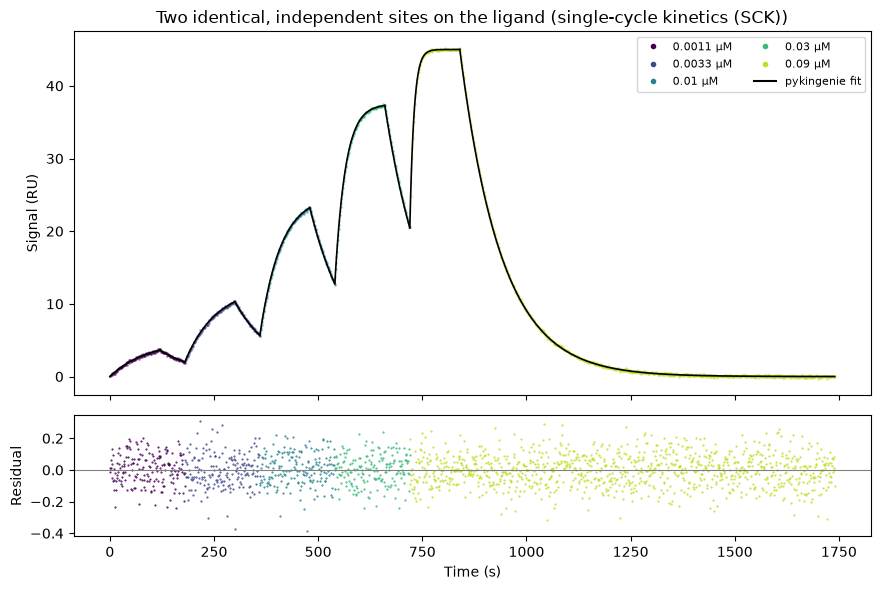

In [7]:
fig = plot_fit(data, fitter, concs, 'Two identical, independent sites on the ligand (single-cycle kinetics (SCK))')